# Churn Model Comparison

The churn outcome is defined as recency greater than 60 days. Recency is deliberately excluded from the predictors to avoid direct target leakage. The random split is a benchmark; future-window labels and a temporal holdout are needed to estimate prospective churn.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import ConfusionMatrixDisplay

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.model import (
    build_features, evaluate, load_and_label, split_and_balance,
    train_logistic, train_random_forest,
)

customers = pd.read_parquet(ROOT / 'data/interim/users_raw.parquet')
rfm = pd.read_parquet(ROOT / 'data/interim/rfm.parquet')
labeled = load_and_label(customers, rfm)
X, y = build_features(labeled)
X_train, X_test, y_train, y_test, scoring_imputer = split_and_balance(X, y)
print(f'Feature rows: {len(X):,}; churn prevalence: {y.mean():.1%}')
print(f'Predictors (recency excluded): {X.columns.tolist()}')

Feature rows: 4,338; churn prevalence: 45.2%
Predictors (recency excluded): ['frequency', 'monetary', 'tenure_days', 'avg_order_value', 'distinct_products', 'distinct_countries', 'total_quantity', 'avg_days_between_orders', 'monetary_per_order', 'product_diversity']


In [2]:
logistic = train_logistic(X_train, y_train)
forest_search = train_random_forest(X_train, y_train)
forest = forest_search.best_estimator_
logistic_metrics = evaluate(logistic, X_test, y_test, 'Logistic Regression')
forest_metrics = evaluate(forest, X_test, y_test, 'Random Forest')
comparison = pd.DataFrame(
    [logistic_metrics, forest_metrics],
    index=['Logistic Regression', 'Random Forest'],
)
display(comparison)
print('Random forest parameters:', forest_search.best_params_)

Logistic Regression: ROC-AUC=0.761, Precision=0.622, Recall=0.784, F1=0.694
Random Forest: ROC-AUC=0.783, Precision=0.631, Recall=0.817, F1=0.712


,roc_auc,precision,recall,f1,accuracy
Logistic Regression,0.760846,0.622222,0.783715,0.693694,0.686636
Random Forest,0.783469,0.630648,0.816794,0.711752,0.700461


Random forest parameters: {'max_depth': 6, 'n_estimators': 200}


In [3]:
importance = pd.Series(
    forest.feature_importances_, index=X.columns, name='random_forest_importance'
).sort_values(ascending=False)
display(importance.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
importance.sort_values().plot.barh(ax=axes[0], title='Random forest feature importance')
coefs = pd.Series(
    logistic.named_steps['logisticregression'].coef_[0], index=X.columns
).sort_values()
coefs.plot.barh(ax=axes[1], title='Logistic regression coefficients')
fig.tight_layout()
fig.savefig(ROOT / 'reports/figures/churn_feature_importance.png', dpi=100)
plt.show()

,random_forest_importance
tenure_days,0.328711
frequency,0.181854
avg_days_between_orders,0.129248
distinct_products,0.117260
total_quantity,0.072286
monetary,0.066044
avg_order_value,0.035405
monetary_per_order,0.035297
product_diversity,0.033530
distinct_countries,0.000364


/var/folders/b6/z2478k910z98r33fnqy5_28h0000gn/T/ipykernel_78834/1888605288.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


/var/folders/b6/z2478k910z98r33fnqy5_28h0000gn/T/ipykernel_78834/3001086713.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


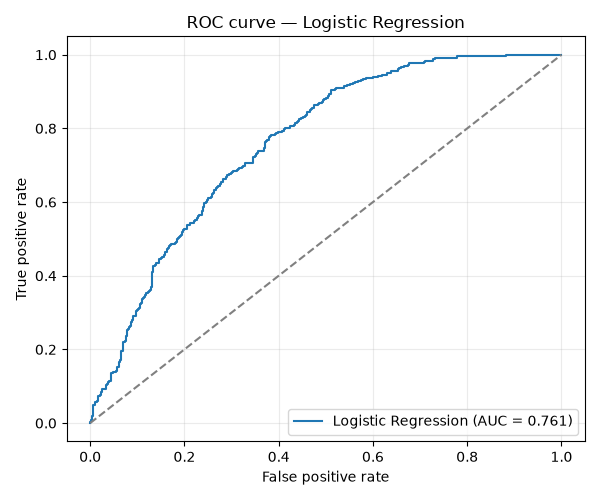

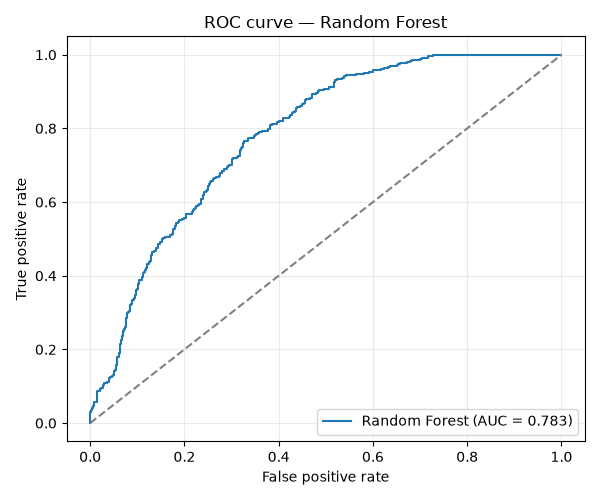

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
ConfusionMatrixDisplay.from_estimator(logistic, X_test, y_test, ax=axes[0])
axes[0].set_title('Logistic regression')
ConfusionMatrixDisplay.from_estimator(forest, X_test, y_test, ax=axes[1])
axes[1].set_title('Random forest')
fig.tight_layout()
fig.savefig(ROOT / 'reports/figures/churn_confusion_matrices.png', dpi=100)
plt.show()

display(Image(filename=str(ROOT / 'reports/figures/roc_logistic_regression.png')))
display(Image(filename=str(ROOT / 'reports/figures/roc_random_forest.png')))